# HDT 6: Boosting e Inferencia Causal

**Ciencia de Datos, Sección A** · Asignada: martes 6 de octubre · **Entrega: martes 13 de octubre, 23:59**

**Nombre:** Ana Sofía Eggenberger

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y splits fijos): las verificaciones son exactas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Dos historias, dos datasets:

**Repartos** (partes A y B): una repartidora quiere predecir cuántos `minutos` toma cada entrega, con `distancia` (km) y `paquetes`. Es el mismo tipo de problema que las tiendas de la sesión 18.

**Socios y el curso de finanzas** (parte C): el banco ofrece un curso de finanzas personales y observa que quienes lo tomaron pagan más puntual. ¿El curso causa la puntualidad? El mismo tipo de trampa que la app de la sesión 19.

Las celdas generan los datos completas; no hay nada que llenar aquí.

In [2]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(6)
m = 350
distancia = rng.uniform(1, 20, m).round(1)
paquetes = rng.integers(1, 9, m)
minutos = (12 + 2.6 * distancia + 3.5 * paquetes + 0.15 * distancia * paquetes
           + rng.normal(0, 6, m)).round(1)
repartos = pd.DataFrame({"distancia": distancia, "paquetes": paquetes, "minutos": minutos})

R_train, R_test = train_test_split(repartos, test_size=0.3, random_state=1)
Xr, yr = R_train[["distancia", "paquetes"]], R_train["minutos"]
Xr_test, yr_test = R_test[["distancia", "paquetes"]], R_test["minutos"]
print("repartos:", len(R_train), "entrenamiento |", len(R_test), "prueba",
      "| promedio del entrenamiento:", round(yr.mean(), 1), "min")

rng_c = np.random.default_rng(60)
n = 2000
antiguedad = rng_c.integers(0, 20, n)
curso = (rng_c.random(n) < 1 / (1 + np.exp(-(antiguedad - 10) / 3))).astype(int)
puntual = (rng_c.random(n) < 1 / (1 + np.exp(-(-0.3 + (antiguedad - 10) / 4)))).astype(int)
socios = pd.DataFrame({"antiguedad": antiguedad, "curso": curso, "puntual": puntual})
print("socios:", len(socios), "| tomaron el curso:", socios["curso"].mean().round(2),
      "| pagan puntual:", socios["puntual"].mean().round(2))

repartos: 245 entrenamiento | 105 prueba | promedio del entrenamiento: 62.6 min
socios: 2000 | tomaron el curso: 0.48 | pagan puntual: 0.42


## Parte A · Boosting: árboles en fila (0.5 pt)

La sesión 18 con otra flota: cada árbol aprende lo que al anterior le faltó, y se agrega una fracción de su corrección.

### Ejercicio 1 (0.20): el paso 0 y el primer árbol

(a) El paso 0: predecir el promedio del entrenamiento para todos. ¿Cuál es el error absoluto promedio en prueba de ese modelo? (b) Entrenar un `DecisionTreeRegressor(max_depth=2, random_state=0)` sobre **lo que falta** (`yr - promedio`). (c) Armar la tabla de los primeros 3 repartos de prueba: minutos reales, predicción del paso 0, lo que falta, lo que agrega el árbol (la mitad de su corrección: paso 0.5) y la nueva predicción.

In [3]:
from sklearn.tree import DecisionTreeRegressor

promedio = yr.mean()
error_promedio = np.mean(np.abs(yr_test - promedio))

arbol1 = DecisionTreeRegressor(max_depth=2, random_state=0)
arbol1.fit(Xr, yr - promedio)

tabla = R_test.head(3).copy()
tabla["pred0"] = round(promedio, 1)
tabla["falta"] = tabla["minutos"] - tabla["pred0"]
tabla["agrega"] = 0.5 * arbol1.predict(tabla[["distancia", "paquetes"]])
tabla["nueva"] = tabla["pred0"] + tabla["agrega"]
print("error del promedio:", round(error_promedio, 1))
print(tabla)

assert round(error_promedio, 1) == 19.7
assert round(tabla["agrega"].iloc[1], 1) == 15.2
assert round(tabla["nueva"].iloc[1], 1) == 77.8

error del promedio: 19.7
     distancia  paquetes  minutos  pred0  falta     agrega      nueva
192       10.6         4     49.8   62.6  -12.8  -2.574082  60.025918
256       14.8         5     85.3   62.6   22.7  15.245009  77.845009
169       12.8         4     67.1   62.6    4.5   2.553756  65.153756


### Ejercicio 2 (0.15): la fila completa

Completar `boosting_a_mano`: en cada vuelta, entrenar un árbol de profundidad 2 sobre lo que falta, sumar `paso` veces su corrección a las predicciones (de entrenamiento y de prueba) y guardar el error de prueba. Correrla con 8 árboles y paso 0.5.

In [4]:
def boosting_a_mano(X, y, X_nuevo, y_nuevo, n_arboles, paso):
    pred = np.full(len(y), y.mean())
    pred_nuevo = np.full(len(y_nuevo), y.mean())
    errores = []
    for _ in range(n_arboles):
        arbol = DecisionTreeRegressor(max_depth=2, random_state=0)
        arbol.fit(X, y - pred)
        pred += paso * arbol.predict(X)
        pred_nuevo += paso * arbol.predict(X_nuevo)
        errores.append(np.mean(np.abs(y_nuevo - pred_nuevo)))
    return errores

errores = boosting_a_mano(Xr, yr, Xr_test, yr_test, n_arboles=8, paso=0.5)
print([round(error, 1) for error in errores])

assert round(errores[0], 1) == 12.7
assert round(errores[-1], 1) == 5.7

[np.float64(12.7), np.float64(9.7), np.float64(7.4), np.float64(6.6), np.float64(6.2), np.float64(6.0), np.float64(5.8), np.float64(5.7)]


### Ejercicio 3 (0.15): qué tanto corregir en cada paso

Correr `boosting_a_mano` con 8 árboles y pasos 0.1, 0.5 y 1.0. Graficar las tres curvas de error (una línea por paso) y responder en un comentario: ¿cuál termina mejor, y qué le pasa a cada extremo?

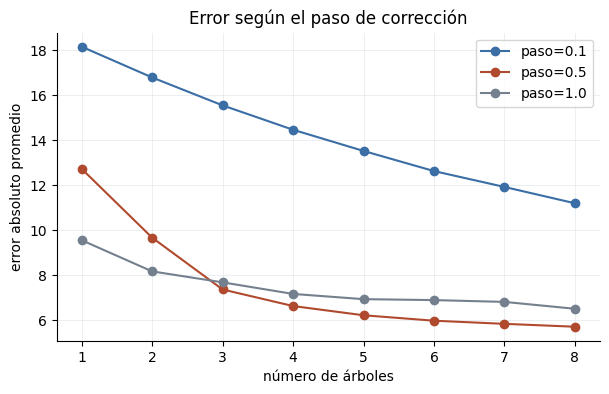

In [5]:
finales = {}
fig, ax = plt.subplots(figsize=(7, 4))
for paso, color in zip([0.1, 0.5, 1.0], [AZUL, ROJO, GRIS]):
    errores_paso = boosting_a_mano(Xr, yr, Xr_test, yr_test, 8, paso)
    finales[paso] = errores_paso[-1]
    ax.plot(range(1, 9), errores_paso, marker="o", color=color,
            label=f"paso={paso}")
ax.set(xlabel="número de árboles", ylabel="error absoluto promedio",
       title="Error según el paso de corrección")
ax.legend()
eje_limpio(ax)
plt.show()

# Respuesta: el paso 0.5 termina mejor; 0.1 avanza lentamente y 1.0 corrige demasiado de golpe.

assert round(finales[0.1], 1) == 11.2
assert round(finales[0.5], 1) == 5.7
assert round(finales[1.0], 1) == 6.5

## Parte B · ¿Bosque o boosting? (0.3 pt)

### Ejercicio 4 (0.15): los tres sobre la misma prueba

Comparar el error absoluto promedio en prueba de: el promedio a secas, un `RandomForestRegressor` (300 árboles, `random_state=0`) y un `HistGradientBoostingRegressor` (`random_state=0`).

In [6]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

bosque = RandomForestRegressor(n_estimators=300, random_state=0)
bosque.fit(Xr, yr)
error_bosque = np.mean(np.abs(yr_test - bosque.predict(Xr_test)))
modelo_boosting = HistGradientBoostingRegressor(random_state=0)
modelo_boosting.fit(Xr, yr)
error_boosting = np.mean(np.abs(yr_test - modelo_boosting.predict(Xr_test)))

print("promedio:", round(error_promedio, 1))
print("bosque:", round(error_bosque, 1))
print("boosting:", round(error_boosting, 1))

assert round(error_bosque, 1) == 5.4
assert round(error_boosting, 1) == 5.3

promedio: 19.7
bosque: 5.4
boosting: 5.3


### Ejercicio 5 (0.15): parar a tiempo

Entrenar `HistGradientBoostingRegressor(max_iter=500, early_stopping=True, validation_fraction=0.15, random_state=0)`. ¿En cuántos árboles se detuvo (`n_iter_`) de los 500 permitidos? ¿Su error en prueba empeoró respecto al ejercicio 4?

In [7]:
temprano = HistGradientBoostingRegressor(
    max_iter=500, early_stopping=True, validation_fraction=0.15,
    random_state=0)
temprano.fit(Xr, yr)
arboles_usados = temprano.n_iter_
error_temprano = np.mean(np.abs(yr_test - temprano.predict(Xr_test)))
print("árboles usados:", arboles_usados, "de 500")
print("error empeoró respecto al ejercicio 4:", error_temprano > error_boosting)

assert arboles_usados == 46
assert round(error_temprano, 1) == 5.6

árboles usados: 46 de 500
error empeoró respecto al ejercicio 4: True


## Parte C · Inferencia causal (1.0 pt)

La sesión 19 con el curso de finanzas: predecir no es intervenir, y la diferencia cruda casi nunca es el efecto.

### Ejercicio 6 (0.20): la diferencia cruda

La tasa de pago puntual de quienes tomaron el curso contra quienes no. Calcular ambas (en %) y la diferencia. Es el número que el gerente quiere presentar; guardarlo para compararlo después.

In [8]:
tasas = socios.groupby("curso")["puntual"].mean() * 100
dif_cruda = tasas.loc[1] - tasas.loc[0]

print("tasa sin curso:", round(tasas.loc[0], 1), "%")
print("tasa con curso:", round(tasas.loc[1], 1), "%")
print("diferencia cruda:", round(dif_cruda, 1), "puntos")
# Respuesta: esta diferencia es observacional y no demuestra por sí sola un efecto causal.

assert round(dif_cruda, 1) == 35.4

tasa sin curso: 25.3 %
tasa con curso: 60.7 %
diferencia cruda: 35.4 puntos


### Ejercicio 7 (0.20): comparar dentro de grupos parecidos

Cortar `antiguedad` en tres niveles con `pd.cut(socios["antiguedad"], [-1, 6, 13, 19], labels=["nuevo", "medio", "veterano"])`. Para cada nivel: la tasa puntual con y sin curso, y su diferencia. Reportar el promedio de las tres diferencias y compararlo con la cruda.

In [9]:
socios["nivel"] = pd.cut(socios["antiguedad"], [-1, 6, 13, 19],
                         labels=["nuevo", "medio", "veterano"])

por_nivel = (socios.groupby(["nivel", "curso"], observed=False)["puntual"]
             .mean().unstack() * 100)
dif_por_nivel = por_nivel[1] - por_nivel[0]
dif_promedio = dif_por_nivel.mean()

print(por_nivel)
print("diferencias por nivel:")
print(dif_por_nivel.round(1))
print("promedio de diferencias:", round(dif_promedio, 1))
# Respuesta: dentro de niveles la diferencia baja mucho; 4.4 es descriptivo, no un efecto causal identificado.

assert round(dif_por_nivel["medio"], 1) == 0.1
assert round(dif_promedio, 1) == 4.4

curso             0          1
nivel                         
nuevo     12.153846  20.731707
medio     42.461538  42.521994
veterano  73.770492  78.188540
diferencias por nivel:
nivel
nuevo       8.6
medio       0.1
veterano    4.4
dtype: float64
promedio de diferencias: 4.4


### Ejercicio 8 (0.20): la paradoja de Simpson

Un programa de tutorías, dos cursos. Calcular la tasa de aprobados por fila, y luego la tasa total de cada grupo (con y sin tutor) juntando los dos cursos. ¿Qué se invierte? ¿A cuál número hay que creerle y por qué?

In [10]:
tutorias = pd.DataFrame({
    "curso": ["Cálculo", "Cálculo", "Álgebra", "Álgebra"],
    "tutor": ["no", "sí", "no", "sí"],
    "estudiantes": [300, 100, 100, 300],
    "aprobaron": [255, 92, 60, 207],
})

tutorias["tasa"] = tutorias["aprobaron"] / tutorias["estudiantes"] * 100
total = tutorias.groupby("tutor")[["estudiantes", "aprobaron"]].sum()
total["tasa"] = total["aprobaron"] / total["estudiantes"] * 100
print(tutorias)
print(total)
# Respuesta: al juntar cursos se invierte la comparación por la distinta composición de los grupos.

assert tutorias["tasa"].tolist() == [85.0, 92.0, 60.0, 69.0]
assert round(total.loc["sí", "tasa"], 2) == 74.75 and round(total.loc["no", "tasa"], 2) == 78.75

     curso tutor  estudiantes  aprobaron  tasa
0  Cálculo    no          300        255  85.0
1  Cálculo    sí          100         92  92.0
2  Álgebra    no          100         60  60.0
3  Álgebra    sí          300        207  69.0
       estudiantes  aprobaron   tasa
tutor                               
no             400        315  78.75
sí             400        299  74.75


Al juntar los cursos, la comparación se invierte porque los grupos tienen distintas cantidades de estudiantes en cada curso. Es mejor comparar dentro de cada curso, ya que así evitamos que las diferencias entre cursos distorsionen el resultado.

### Ejercicio 9 (0.20): importante para predecir no es causa

Dos logísticas para predecir `puntual`: el modelo A solo con `curso`; el modelo B con `curso` y `antiguedad`. Comparar el coeficiente de `curso` en cada una. ¿Qué le pasa cuando la causa real entra al modelo?

In [11]:
from sklearn.linear_model import LogisticRegression

modelo_a = LogisticRegression().fit(socios[["curso"]], socios["puntual"])
modelo_b = LogisticRegression().fit(
    socios[["curso", "antiguedad"]], socios["puntual"])

coef_curso_a = modelo_a.coef_[0, 0]
coef_curso_b = modelo_b.coef_[0, 0]

print("coeficiente de curso, modelo A:", round(coef_curso_a, 2))
print("coeficiente de curso, modelo B:", round(coef_curso_b, 2))
print("coeficiente de antigüedad, modelo B:", round(modelo_b.coef_[0, 1], 2))
# Respuesta: al incluir antigüedad, el coeficiente de curso cambia de signo; esto muestra confusión, no prueba causalidad.

assert round(coef_curso_a, 2) == 1.5
assert round(coef_curso_b, 2) == -0.08

coeficiente de curso, modelo A: 1.5
coeficiente de curso, modelo B: -0.08
coeficiente de antigüedad, modelo B: 0.24


/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_m

### Ejercicio 10 (0.20): el colisionador, con dos monedas

Tirar dos monedas independientes 4,000 veces (`np.random.default_rng(61).integers(0, 2, 4000)` para cada una, en ese orden). (a) Su correlación: debe ser ~0. (b) Filtrar solo las tiradas donde salió al menos una cara y recalcular la correlación entre las que pasaron el filtro. ¿Qué apareció?

In [12]:
rng_m = np.random.default_rng(61)
moneda1 = rng_m.integers(0, 2, 4000)
moneda2 = rng_m.integers(0, 2, 4000)

corr_sin_filtro = np.corrcoef(moneda1, moneda2)[0, 1]
pasan = (moneda1 == 1) | (moneda2 == 1)
corr_filtrada = np.corrcoef(moneda1[pasan], moneda2[pasan])[0, 1]
print("correlación sin filtro:", round(corr_sin_filtro, 2))
print("correlación filtrada:", round(corr_filtrada, 2))

# Respuesta: filtrar por al menos una cara crea una dependencia negativa entre monedas que eran independientes.

assert abs(corr_sin_filtro) < 0.05
assert round(corr_filtrada, 2) == -0.49

correlación sin filtro: 0.02
correlación filtrada: -0.49


## Parte D · Criterio (0.2 pt)

### Ejercicio 11 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** El gerente propone: "los del curso pagan 35 puntos mejor; hagámoslo obligatorio y la puntualidad sube 35 puntos". Con los ejercicios 6, 7 y 9, explicar qué está mal y qué subida es realista esperar.

**(b)** ¿Qué tendría que hacer el banco para medir el efecto REAL del curso? Describir el diseño en 2-3 líneas y explicar por qué resuelve el problema que los datos observados no pueden resolver.

**Respuesta (a):** La diferencia cruda fue 35.4 puntos, pero dentro de antigüedad fue 8.6, 0.1 y 4.4, con promedio 4.4; además, el coeficiente de curso pasó de 1.50 a −0.08 al ajustar.  
Por eso hay confusión y no se puede asegurar una subida causal de 35 puntos ni una subida real concreta con estos datos.

**Respuesta (b):** Asignaría socios comparables al azar a recibir una oferta del curso o a un grupo control y compararía su puntualidad posterior.  
La asignación reduce la confusión; si asistir no es obligatorio, el experimento mide el efecto de ofrecer el curso, no necesariamente el efecto de asistir.

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

- Se utilizó AI para revisar las explicaciones sobre la paradoja de Simpson y la diferencia entre correlación y causalidad.